# 01 – Khám phá dữ liệu AG News (Exploratory Data Analysis)
**Coursework Topic 6 – News Topic Classification Using Transformer-Based Models**

Mục tiêu của notebook:
1. Kiểm tra quy mô, cấu trúc các tập `train` (108,000), `val` (12,000), `test` (7,600) trong `data/processed/`.
2. Kiểm tra tính toàn vẹn dữ liệu (giá trị thiếu, chuỗi rỗng, mẫu trùng lặp).
3. Phân tích phân bố 4 chủ đề (`World`, `Sports`, `Business`, `Sci/Tech`).
4. Thống kê độ dài văn bản theo **số từ (words)** và **số lượng subword tokens** (`distilbert-base-uncased`) để chọn `max_len` hợp lý cho mô hình Transformer.
5. Xem xét mẫu dữ liệu tiêu biểu và minh họa hiệu quả của bước tiền xử lý (`clean_text`).

## 1. Khởi tạo môi trường & Nạp dữ liệu đã tiền xử lý
- **Mục đích:** Khai báo các thư viện phân tích dữ liệu (`pandas`, `numpy`, `matplotlib`), nạp module `src/data.py` của nhóm và đọc 3 tập dữ liệu đã chia sẵn từ `data/processed/` (`train.csv`, `val.csv`, `test.csv`).
- **Kết quả kỳ vọng:** Xác nhận kích thước chuẩn của từng tập (`108,000` train / `12,000` validation / `7,600` test) và xem trước cấu trúc 3 cột (`text`, `label`, `label_name`).

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

import data
from data import LABEL_NAMES, DEFAULT_MODEL_NAME, clean_text

plt.rcParams["figure.dpi"] = 110

splits = data.prepare_and_save_splits()
train_df, val_df, test_df = splits["train"], splits["val"], splits["test"]

print(f"Train shape : {train_df.shape}")
print(f"Val shape   : {val_df.shape}")
print(f"Test shape  : {test_df.shape}")
train_df.head()

Train shape : (108000, 3)
Val shape   : (12000, 3)
Test shape  : (7600, 3)


,text,label,label_name
0,10 seconds that change everything ATHENS - Ten...,1,Sports
1,Charline Labonte rises to challenge Charline L...,1,Sports
2,Ex-El Paso Traders Plead Guilty to False Repor...,2,Business
3,Brit deal 'one year only Even if British and F...,1,Sports
4,"Signed, Sealed, Delivered CHICAGO - The Cubs a...",1,Sports


## 2. Kiểm tra tính toàn vẹn & Chất lượng dữ liệu
- **Mục đích:** Rà soát các lỗi dữ liệu phổ biến trước khi đưa vào huấn luyện, bao gồm giá trị thiếu (`Null`), chuỗi rỗng (`Empty`) và các bản ghi văn bản trùng lặp hoàn toàn (`Exact duplicates`) trên cả 3 tập.
- **Ý nghĩa:** Đảm bảo dữ liệu sạch, không gây lỗi khi tokenize và kiểm soát mức độ trùng lặp mẫu giữa các bản ghi.

In [2]:
for name, df in splits.items():
    n_null = df["text"].isna().sum()
    n_empty = (df["text"].astype(str).str.strip() == "").sum()
    n_dup = df.duplicated(subset=["text"]).sum()
    print(f"[{name.upper():5s}] Null: {n_null} | Empty: {n_empty} | Exact duplicates: {n_dup}")

[TRAIN] Null: 0 | Empty: 0 | Exact duplicates: 62
[VAL  ] Null: 0 | Empty: 0 | Exact duplicates: 3
[TEST ] Null: 0 | Empty: 0 | Exact duplicates: 0


## 3. Phân tích phân bố nhãn (Class Distribution)
- **Mục đích:** Thống kê số lượng và tỷ lệ phần trăm của 4 chủ đề (`World`, `Sports`, `Business`, `Sci/Tech`) trên các tập Train, Validation và Test, đồng thời trực quan hóa bằng biểu đồ cột.
- **Ý nghĩa:** Xác minh tính cân bằng tuyệt đối (25% mỗi lớp) sau bước lấy mẫu phân tầng (`stratified split`), làm cơ sở lựa chọn độ đo đánh giá **Accuracy** và **Macro F1-score**.

,Train (n),Val (n),Test (n),Train (%)
label_name,,,,
World,27000,3000,1900,25.0
Sports,27000,3000,1900,25.0
Business,27000,3000,1900,25.0
Sci/Tech,27000,3000,1900,25.0


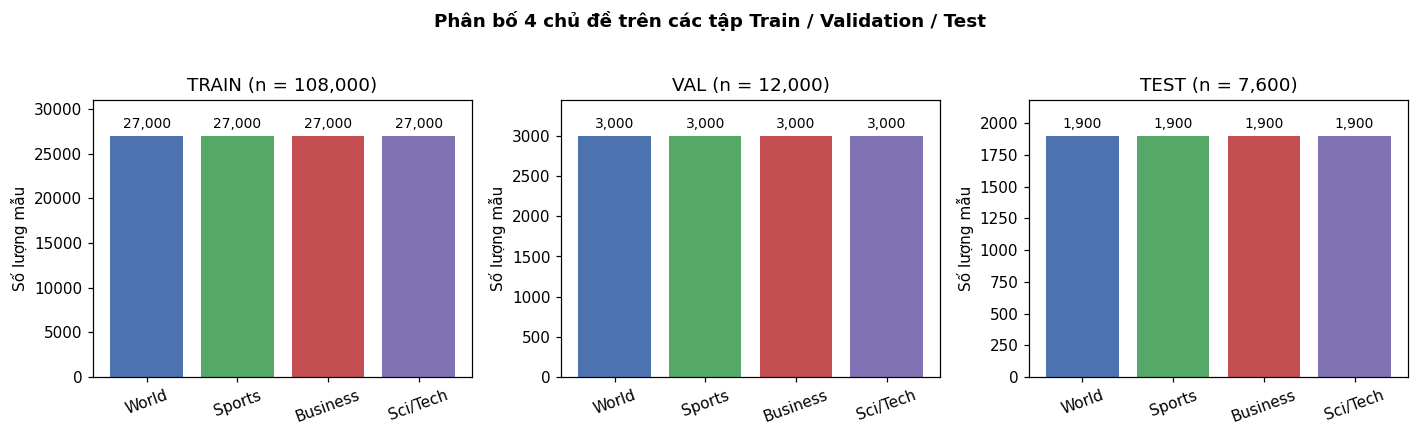

In [3]:
dist_df = pd.DataFrame({
    "Train (n)": train_df["label_name"].value_counts().reindex(LABEL_NAMES),
    "Val (n)": val_df["label_name"].value_counts().reindex(LABEL_NAMES),
    "Test (n)": test_df["label_name"].value_counts().reindex(LABEL_NAMES),
})
dist_df["Train (%)"] = (dist_df["Train (n)"] / len(train_df) * 100).round(2)
display(dist_df)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3"]

for ax, (split_name, df) in zip(axes, splits.items()):
    counts = df["label_name"].value_counts().reindex(LABEL_NAMES)
    bars = ax.bar(LABEL_NAMES, counts.values, color=colors)
    ax.set_title(f"{split_name.upper()} (n = {len(df):,})")
    ax.set_ylabel("Số lượng mẫu")
    ax.set_ylim(0, counts.max() * 1.15)
    ax.tick_params(axis="x", rotation=20)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + counts.max() * 0.02,
                f"{int(h):,}", ha="center", va="bottom", fontsize=9)

plt.suptitle("Phân bố 4 chủ đề trên các tập Train / Validation / Test", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Thống kê độ dài văn bản (Word Count & DistilBERT Token Count)
- **Mục đích:** Tính toán các chỉ số thống kê mô tả (trung bình, độ lệch chuẩn, trung vị, các phân vị 90%, 95%, 99% và giá trị lớn nhất) về số lượng từ và số lượng subword token của `distilbert-base-uncased` trên tập Train.
- **Ý nghĩa:** Đo lường tỷ lệ bao phủ dữ liệu tại các ngưỡng `max_len` (`64`, `128`, `256`) để làm căn cứ cho quyết định `max_len` (xem mục **8. EDA → Decision** ở cuối notebook). Lưu ý: 128 là mức bao phủ gần đủ, còn các mô hình Transformer của project thực tế chạy với `max_len = 64`.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(DEFAULT_MODEL_NAME)

# Tính số từ trên toàn bộ tập train
train_word_lens = train_df["text"].str.split().str.len()

# Tính số subword token bằng batch encoding nhanh trên toàn bộ tập train
encodings = tokenizer(
    train_df["text"].tolist(),
    truncation=False,
    add_special_tokens=True,
    return_attention_mask=False,
    return_token_type_ids=False,
)
train_token_lens = pd.Series([len(ids) for ids in encodings["input_ids"]])

stats = pd.DataFrame({
    "Word count": train_word_lens.describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
    "DistilBERT token count": train_token_lens.describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
}).round(2)
display(stats)

for max_len in [64, 128, 256]:
    cov = (train_token_lens <= max_len).mean() * 100
    print(f"Tỷ lệ mẫu không bị cắt (token <= {max_len:3d}): {cov:.2f}%")

,Word count,DistilBERT token count
count,108000.00,108000.00
mean,37.98,51.77
std,10.20,17.62
min,8.00,14.00
50%,37.00,49.00
90%,48.00,67.00
95%,53.00,78.00
99%,70.00,116.00
max,171.00,327.00


Tỷ lệ mẫu không bị cắt (token <=  64): 87.41%
Tỷ lệ mẫu không bị cắt (token <= 128): 99.42%
Tỷ lệ mẫu không bị cắt (token <= 256): 99.97%


## 5. Trực quan hóa phân phối độ dài chuỗi Token
- **Mục đích:** Vẽ biểu đồ tần suất (Histogram) phân phối độ dài subword token của toàn bộ tập Train và đánh dấu hai mốc cắt ngưỡng `max_len = 64` (đỏ) và `max_len = 128` (xanh lá).
- **Ý nghĩa:** Minh họa trực quan phần lớn bài báo tập trung ở khoảng 35–65 token và ngưỡng `128` bao phủ gần như toàn bộ phần đuôi của phân phối (`99.42%`).
- **Lưu ý:** tại `max_len = 64` (giá trị thực tế dùng khi huấn luyện) chỉ `87.41%` mẫu không bị cắt, tức `12.59%` bài báo bị cắt.


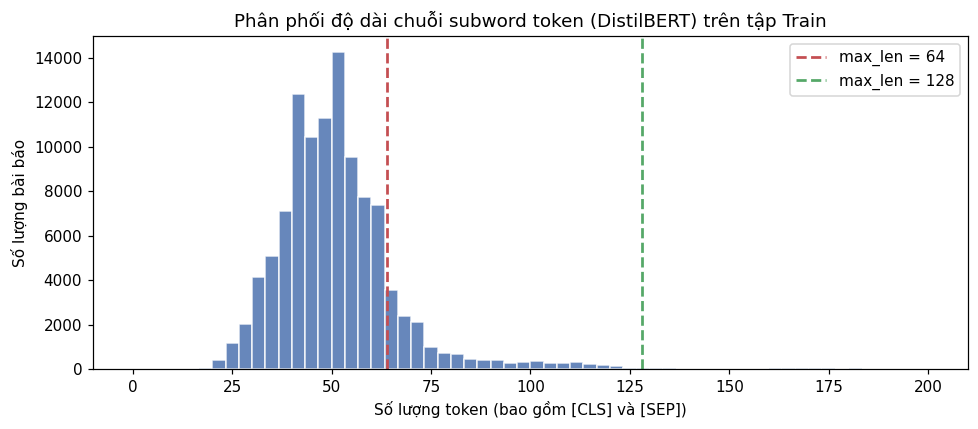

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(train_token_lens, bins=60, range=(0, 200), color="#4C72B0", edgecolor="white", alpha=0.85)
ax.axvline(64, color="#C44E52", linestyle="--", linewidth=1.8, label="max_len = 64")
ax.axvline(128, color="#55A868", linestyle="--", linewidth=1.8, label="max_len = 128")
ax.set_title("Phân phối độ dài chuỗi subword token (DistilBERT) trên tập Train")
ax.set_xlabel("Số lượng token (bao gồm [CLS] và [SEP])")
ax.set_ylabel("Số lượng bài báo")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Khảo sát mẫu tiêu biểu & Hiệu quả hàm tiền xử lý (`clean_text`)
- **Mục đích:** Trích xuất ví dụ thực tế của từng chủ đề để quan sát văn phong tin tức AG News và kiểm chứng khả năng làm sạch nhiễu HTML entities (`#39;`, `&amp;`), dấu gạch chéo thoát ký tự (`\$`) của hàm `clean_text`.
- **Ý nghĩa:** Xác nhận văn bản giữ nguyên được ngữ cảnh và định dạng tự nhiên cho cả mô hình TF-IDF lẫn Transformer.

In [6]:
print("=== MẪU TIÊU BIỂU CỦA 4 CHỦ ĐỀ ===")
for label_name in LABEL_NAMES:
    sample_text = train_df[train_df["label_name"] == label_name]["text"].iloc[0]
    print(f"\n[{label_name}]\n{sample_text}")

print("\n=== MINH HỌA TIỀN XỬ LÝ (CLEAN_TEXT) ===")
noisy_examples = [
    "Special to ESPN.com It #39;s the age old quest for victory.",
    "Dow Jones Agrees to Buy MarketWatch in \\$519 Million Deal &amp; More",
]
for raw in noisy_examples:
    print(f"Trước : {raw}")
    print(f"Sau   : {clean_text(raw)}\n")

=== MẪU TIÊU BIỂU CỦA 4 CHỦ ĐỀ ===

[World]
Explosions caused mushroom cloud over N. Korea: source SEOUL, SOUTH KOREA - A mushroom-shaped cloud was seen in North Korea last Thursday following a large explosion, a South Korean news agency reported Sunday.

[Sports]
10 seconds that change everything ATHENS - Ten seconds. Barely time enough to tie a shoe, wash a glass, get the paper off the porch. But when the moment comes, and eight men kneel at their blocks and peer down the empty, waiting track, it is as if the entire Olympics stop to watch.

[Business]
Ex-El Paso Traders Plead Guilty to False Reports Two more former natural gas traders for El Paso Corp. have pleaded guilty to reporting bogus deals in a widening investigation of the industry, the US Attorney 's Office said.

[Sci/Tech]
XBox Owner Sues Microsoft drusoicy writes quot;Reuters is reporting that Sean Burke has filed suit against Microsoft because his XBox system stopped reading discs (games or otherwise) after less than one

## 7. Kiểm tra bổ sung: văn bản trùng nhưng khác nhãn, rò rỉ giữa các tập
- **Mục đích:** Kiểm tra xem 62 bản sao trong train có phải chỉ là trùng lặp vô hại hay còn mang nhãn xung đột, và đo mức rò rỉ giữa train/val/test.
- **Ý nghĩa:** Cung cấp bằng chứng để quyết định có cần loại bản trùng/huấn luyện lại hay không, đồng thời cho thấy nhãn AG News có chỗ mơ hồ (liên quan trực tiếp tới Error Analysis).


In [7]:
# Văn bản trùng nhưng KHÁC nhãn, và rò rỉ giữa các tập (cơ sở cho Decision D2)
dup = train_df[train_df.duplicated("text", keep=False)]
groups = dup.groupby("text")["label_name"].agg(lambda s: tuple(sorted(set(s))))
conflict = groups[groups.map(len) > 1]
print(f"Train: {train_df.duplicated('text').sum()} bản sao thừa ({train_df.duplicated('text').mean():.3%}); "
      f"{len(conflict)}/{len(groups)} nhóm trùng văn bản nhưng KHÁC nhãn")
print(conflict.value_counts().to_string())
print(f"Rò rỉ: train∩val = {len(set(train_df.text) & set(val_df.text))}, "
      f"train∩test = {len(set(train_df.text) & set(test_df.text))}, "
      f"val∩test = {len(set(val_df.text) & set(test_df.text))}")
print("Số từ trung bình theo lớp (train):")
print(train_df.assign(words=train_word_lens).groupby("label_name")["words"].mean().round(1).reindex(LABEL_NAMES).to_string())


Train: 62 bản sao thừa (0.057%); 9/62 nhóm trùng văn bản nhưng KHÁC nhãn
label_name
(Business, Sci/Tech)    6
(Business, World)       2
(Sci/Tech, World)       1
Rò rỉ: train∩val = 19, train∩test = 4, val∩test = 0
Số từ trung bình theo lớp (train):
label_name
World       39.0
Sports      37.8
Business    37.7
Sci/Tech    37.4


## 8. EDA → Decision
**Evidence → quyết định của nhóm** (số liệu lấy từ các ô ở trên; bản đầy đủ: `docs/results/decision_log.md` mục 1).

| # | Quan sát (Evidence) | Quyết định (Decision) | Vì sao |
|---|---|---|---|
| D1 | Null = 0, Empty = 0 ở cả 3 tập | Không cần xử lý thiếu dữ liệu | Không có mẫu lỗi |
| D2 | Train có 62 bản sao thừa (0,057%); 9 nhóm trùng văn bản nhưng khác nhãn; train∩test = 4 (0,05% test) | **Giữ nguyên**, không loại và không huấn luyện lại; ghi là hạn chế | Ảnh hưởng tối đa ≈ 0,05 điểm % < sai số test ±0,6 điểm %; huấn luyện lại tốn hàng chục phút/mô hình |
| D3 | 4 lớp cân bằng đúng 25% | Dùng **Accuracy + Macro F1 + chỉ số theo từng lớp**; không dùng class weight/resampling | Lớp cân bằng; chỉ số tổng có thể che lỗi riêng của Business/Sci-Tech |
| D4 | Có nhiễu HTML (`#39;`, `&amp;`) | Dùng chung `clean_text` cho cả 3 phương pháp | So sánh công bằng, đã kiểm chứng ở mục 6 |
| D5 | p90 = 67 token; `max_len=64` bao phủ 87,41%, `128` bao phủ 99,42% | **`max_len = 64`** cho Frozen Encoder và Fine-Tuning (đúng với giá trị đã chạy) | Chi phí tính toán trên CPU/GPU hạn chế; đánh đổi: 12,59% bài bị cắt |

**Đính chính:** phiên bản trước của notebook ghi "chọn `max_len = 128`" nhưng mô hình thực tế chạy `max_len = 64`; đã sửa cho khớp.

**Còn thiếu:** chưa chạy thử `max_len = 128`. Bài dài (> 60 từ) có tỉ lệ sai cao gấp ~1,7 lần mức chung ở Baseline (không bị cắt) và ~2,2 lần ở Frozen Encoder (bị cắt) → gợi ý, chưa phải bằng chứng, rằng việc cắt có tác động; cần một lần chạy Fine-Tuning với `max_len = 128` để kết luận.
